# Binary Classifiers

Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2025-08-26.  
Copyright (c) 2020-2025, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  


ref:
* exploreLFC.ipynb
* binary.vs.multclassifiers.ipynb

## Sensitivity and Specificity
In medical or safety-critical models, missing a positive case (false negative) can be more costly than raising false alarms. Often patients what are predicted to be positive are tested a second time to reduce the possiblity of a false positive.

Sensitivity is the True positive rate = tp / (TP + fn)
Specificity is the True negative rate.    

The output of our model is a probabilty distribution. We choose a decison threshold (0.5 by default) to decide if a sample is 'positive'. By adjusting that threshold we can trade off sensitivity and specificity. 

Increasing sensitivity → catch more positives → usually more false positives (lower specificity).  

Increasing specificity → fewer false positives → miss more true positives (lower sensitivity).  

Often a threshold is choosen so that 90% of actual positive samples where correctly detected. You can use an ROC curve to find this decision threshold for any give sensitivity.   

Next you look at other metrics that operate at that point to evaluate the model. for example Specificity (true negative rate), AUC/ROC, or Precision / Positive predictive value → how many predicted positives were actually correct

**dataset : shrunk200DataSetConfig_G 2026-01-04**. 
|    | diagnosis   |   Target Specificity |   Sensitivity (TPR) |   Achieved Specificity (TNR) |   Approx. Threshold |      auc |   nSimTrainSamples |   nSimTrainFeatures |   nRealTestSamples |   nRealTestFeatures |
|---:|:------------|---------------------:|--------------------:|-----------------------------:|--------------------:|---------:|-------------------:|--------------------:|-------------------:|--------------------:|
|  0 | Colorectal  |                  0.9 |            0.924528 |                          0.9 |               0.357 | 0.959193 |               7999 |                 200 |                 96 |                 200 |
|  1 | Esophagus   |                  0.9 |            0.424194 |                          0.9 |               1     | 0.854839 |                879 |                  22 |                 74 |                  22 |
|  2 | Liver       |                  0.9 |            0.923077 |                          0.9 |               0.21  | 0.974955 |               7999 |                 200 |                 69 |                 200 |
|  3 | Lung        |                  0.9 |            0.942857 |                          0.9 |               0.792 | 0.982392 |               6000 |                 150 |                 78 |                 150 |
|  4 | Stomach     |                  0.9 |            0.722222 |                          0.9 |               0.827 | 0.936047 |               7999 |                 200 |                 79 |                 200 |

In [1]:
defaultNotebookName="binaryClassifiers"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-10-20 13:15:43,426 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-10-20 13:15:43,426 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/fagazi/src/python:/private/home/aedavids/fagazi/src/jupyterNotebooks]
2026-10-20 13:15:43,427 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/fagazi/src/python/cliUtilities.py]
2026-10-20 13:15:43,427 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI]


In [2]:
# use fitz to display pdf
import fitz
import glob
from IPython.display import display
# from IPython.display import HTML
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.axes import Axes
from matplotlib.patches import Patch

import numpy as np
import os
import pandas as pd
from pathlib import Path
import pprint as pp
import time
# local imports
from notebookUtils import appendToPYTHONPATH, getNotebookName

ORIG_PYTHONPATH = os.environ['PYTHONPATH']

extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'
appendToPYTHONPATH([extraRNA_PythonPath1, extraRNA_PythonPath2]) 

from archive.dataTypes import  ModelConfig
from archive.saveDataTypes import archive 
from models.configMLWorkflow import configBinaryLoadAndSplit, configBinaryCalculateSensitivityAtSpecificity
from models.configMLWorkflow import configConfusionPanel, configEvaluate
from models.configMLWorkflow import configROCPanel, configVolcanoPanel
from models.mlWorkflow import trainRandomForest
# from plots.sensitivity_at_specificity import computeSensitivitiesAtTargets
from plots.plotPanel import combineFigures, combineFiguresLayout, displayPDFInNotebook, getSubplotWidthAndHeight
from plots.plotPanel import Panel, setFigureFont
from plots.plotUtilities import saveDataFrameImage

notebook_start_time = time.time()
print("⏱️ Notebook started.")

2026-10-20 13:15:44,521 WARNING notebookUtils.py appendToPYTHONPATH() line:40] [Updated PYTHONPATH: /private/home/aedavids/fagazi/src/python:/private/home/aedavids/fagazi/src/jupyterNotebooks:/private/home/aedavids/extraCellularRNA:/private/home/aedavids/extraCellularRNA/src]


⏱️ Notebook started.


In [3]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'

notebookName: binaryClassifiers
notebookDir: /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI


In [4]:
# _G : global use to insure we do not pick up globals in function by accident 
# durring refactoring

simulatedDataRootDir_G = "/private/groups/kimlab/aedavids/fagazi/simulatedData"

realDataRoot_G = "/private/groups/kimlab/data/elife"
realDataPath_G = f'{realDataRoot_G}/elife_all_norm_counts_2023-05-18.csv'
realMetaDataPath_G = f'{realDataRoot_G}/elife_scaled_metaData_2023-05-18.csv'

In [5]:
shrunkDataSetConfig_G = ModelConfig(
                        dataSetName = "shrunkBest20",
                        rootOutDir = notebookOutDir,
                        # simulatedDataPath = f"{simulatedDataRootDir_G}/generateSamplesBinaryShurnk.sh.out_bestShrunk20",
                        simulatedDataPath = f"{simulatedDataRootDir_G}/generateSamplesBinaryShurnk.sh.out_best20_lfcShrink",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results.lfcShrink',
                    )

# ran twice
# first time is to get plot 
# figure out what the abstract should be
# run second time to store the abstract in the archive
shrunkDataSetConfig_G.abstract = "For each of the 5 cancer types in the normalized elife data set, \nwe trained"\
                        + " a random forest using the best 20 differential expressed cancer_type vs. healthy doner "


shrunk200DataSetConfig_G = ModelConfig(
                        dataSetName = "shrunkBest200",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{simulatedDataRootDir_G}/generate200lfcShrink.sh.out_best200_lfcShrink",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results.lfcShrink',
                    )
shrunk200DataSetConfig_G.abstract = "much better results when compared to shrunkBest20. areas needing improvement."\
    + "\n 1) colorectal TP = 79% healthy TP = 74. Esoph only has 23 features?. TODO explore feature importance. make sure we are not learning noise. "\
        + "\n check MI, check basemean"


best200DataSetConfig_G = ModelConfig(
                        dataSetName = "best200",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{simulatedDataRootDir_G}/generate200.sh.out_best200_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                    )
best200DataSetConfig_G.abstract = "not much difference with shrunk200 data set"


# runConfig = shrunkDataSetConfig_G # debug version, runs fast 20 features
# runConfig = best200DataSetConfig_G
runConfig = shrunk200DataSetConfig_G # best sensitivity does slightly better 


## Train binary classifier

In [6]:
print(f'{runConfig.dataSetName}')
configBinaryLoadAndSplit( runConfig, diagnosis=["Colorectal", "Esophagus", "Liver", "Lung", "Stomach"] )

2026-10-20 13:15:46,043 WARNING configMLWorkflow.py configBinaryLoadAndSplit() line:104] [loading /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-10-20 13:15:46,044 WARNING configMLWorkflow.py configBinaryLoadAndSplit() line:105] [loading /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]
2026-10-20 13:15:46,045 WARNING configMLWorkflow.py configBinaryLoadAndSplit() line:106] [loading /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink]


shrunkBest200


2026-10-20 13:15:46,835 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Colorectal/formatSynthetics.py.out/X.csv]
2026-10-20 13:15:48,354 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Colorectal/formatSynthetics.py.out/y.csv]
2026-10-20 13:15:50,167 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-10-20 13:15:52,585 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]
2026-10-20 13:15:54,820 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Esophagus/formatSynthetics.py.out/X.csv]
2026-10-20 13:15:55

In [7]:
# add the path to the DESeqResults
# if runConfig.deseqResultsRootPath:
# this will not work for multiclassifiers
for key, db in runConfig.dataDict.items():
    drType = runConfig.deseqResultsType
    print(f'key : {key} drType : {drType}')    
    tList = glob.glob( f'{runConfig.simulatedDataPath}/{key}/*/*.{drType}' )
    print(f't : \n{tList[0]}')
    
    # only generate volcano plot on the trained model bundle.
    # all the other mb's will have the same features
    db.simTrain.deseqResultsPath = tList[0]

key : Colorectal drType : results.lfcShrink
t : 
/private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Colorectal/elife-design-tilda_gender_category-padj-0001-lfc-20-n-200/Colorectal_vs_Healthy_donor.results.lfcShrink
key : Esophagus drType : results.lfcShrink
t : 
/private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Esophagus/elife-design-tilda_gender_category-padj-0001-lfc-20-n-200/Esophagus_vs_Healthy_donor.results.lfcShrink
key : Liver drType : results.lfcShrink
t : 
/private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Liver/elife-design-tilda_gender_category-padj-0001-lfc-20-n-200/Liver_vs_Healthy_donor.results.lfcShrink
key : Lung drType : results.lfcShrink
t : 
/private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Lung/elife-design-tilda_gender_category-padj-0001-lfc-20-n-200/Lung_vs_Healthy_donor.re

In [8]:
trainRandomForest( runConfig.dataDict, n_estimators=1000 )

2026-10-20 13:16:19,224 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (7999, 200) y.shape : (7999,)]


Colorectal


2026-10-20 13:16:45,690 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (879, 22) y.shape : (879,)]


Esophagus


2026-10-20 13:16:48,003 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (7999, 200) y.shape : (7999,)]


Liver


2026-10-20 13:17:09,334 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (6000, 150) y.shape : (6000,)]


Lung


2026-10-20 13:17:31,397 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (7999, 200) y.shape : (7999,)]


Stomach


## Evaluate binary classifiers

In [9]:
configEvaluate( runConfig )

diganosis : Colorectal dataSet : simTrain


2026-10-20 13:17:58,881 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Colorectal_Cancer-simTrain.png]
2026-10-20 13:17:59,886 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Colorectal_Cancer-simTrain.pdf]
2026-10-20 13:18:01,215 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Colorectal_Cancer-simTrain.png]
2026-10-20 13:18:01,309 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Colorectal_Cancer-simTrain.pdf]
2026-10-20 13:18:12,075 WARNING font_manager.py _fin

diganosis : Esophagus dataSet : simTrain


2026-10-20 13:18:13,738 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Esophagus_Cancer-simTrain.png]
2026-10-20 13:18:14,560 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Esophagus_Cancer-simTrain.pdf]
2026-10-20 13:18:15,417 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Esophagus_Cancer-simTrain.png]
2026-10-20 13:18:15,522 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Esophagus_Cancer-simTrain.pdf]
2026-10-20 13:18:16,747 WARNING archiveUtilities.py save

diganosis : Liver dataSet : simTrain


2026-10-20 13:18:18,371 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Liver_Cancer-simTrain.png]
2026-10-20 13:18:19,204 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Liver_Cancer-simTrain.pdf]
2026-10-20 13:18:20,393 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Liver_Cancer-simTrain.png]
2026-10-20 13:18:20,500 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Liver_Cancer-simTrain.pdf]
2026-10-20 13:18:22,855 WARNING archiveUtilities.py saveFigure() line:20

... (30 outputs left out)

diganosis : Lung dataSet : real


2026-10-20 13:19:14,409 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Lung_Cancer-real.png]
2026-10-20 13:19:15,255 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Lung_Cancer-real.pdf]
2026-10-20 13:19:16,098 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Lung_Cancer-real.png]
2026-10-20 13:19:16,203 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Lung_Cancer-real.pdf]


diganosis : Stomach dataSet : real


2026-10-20 13:19:17,247 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Stomach_Cancer-real.png]
2026-10-20 13:19:18,075 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/confusionMatrix_Stomach_Cancer-real.pdf]
2026-10-20 13:19:18,897 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Stomach_Cancer-real.png]
2026-10-20 13:19:19,003 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/roc_Stomach_Cancer-real.pdf]


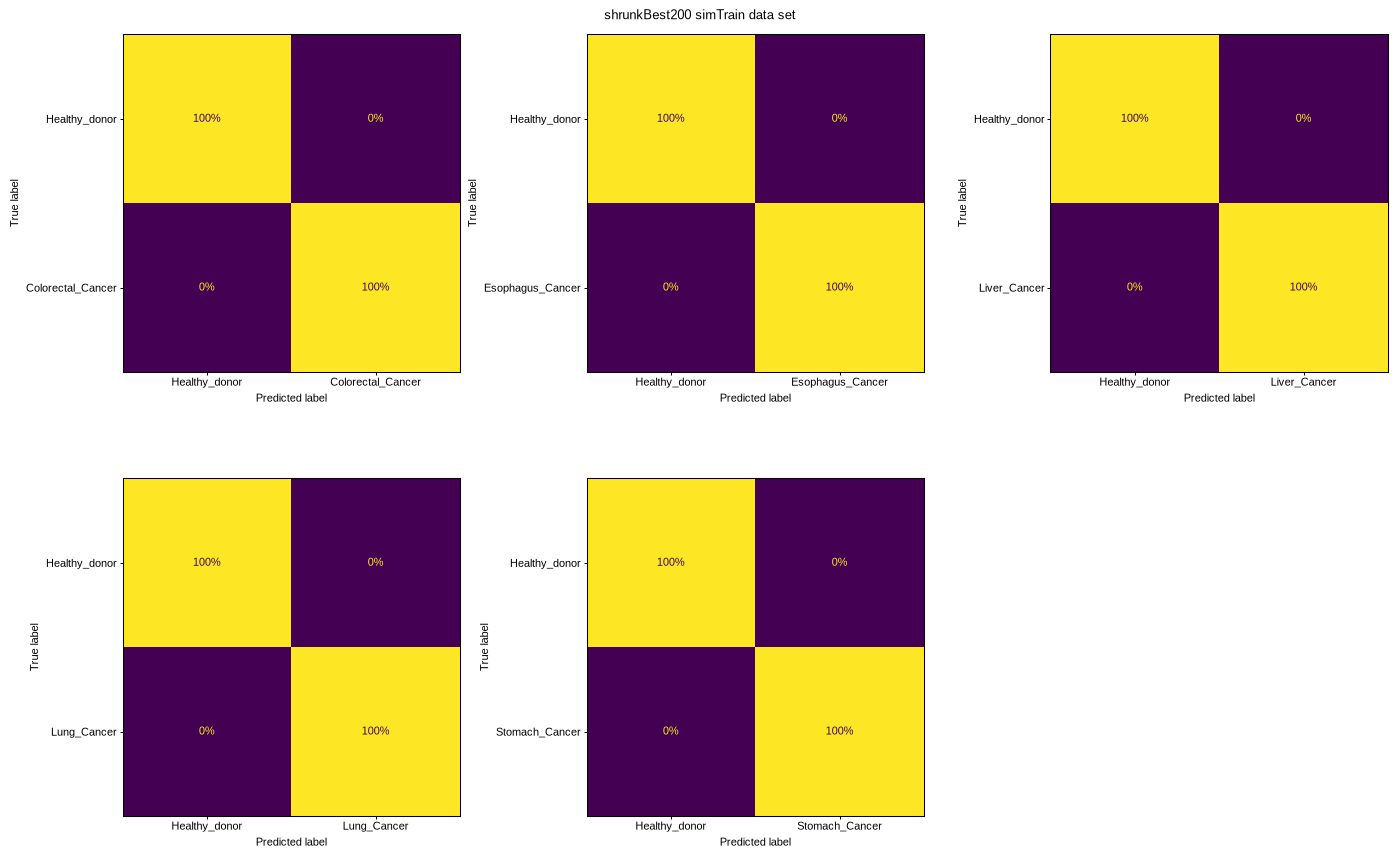

2026-10-20 13:19:22,782 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/confusionMatrix_shrunkBest200-simTrain-data-set.png]
2026-10-20 13:19:25,317 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/confusionMatrix_shrunkBest200-simTrain-data-set.pdf]


In [10]:
configConfusionPanel( runConfig, "simTrain" )

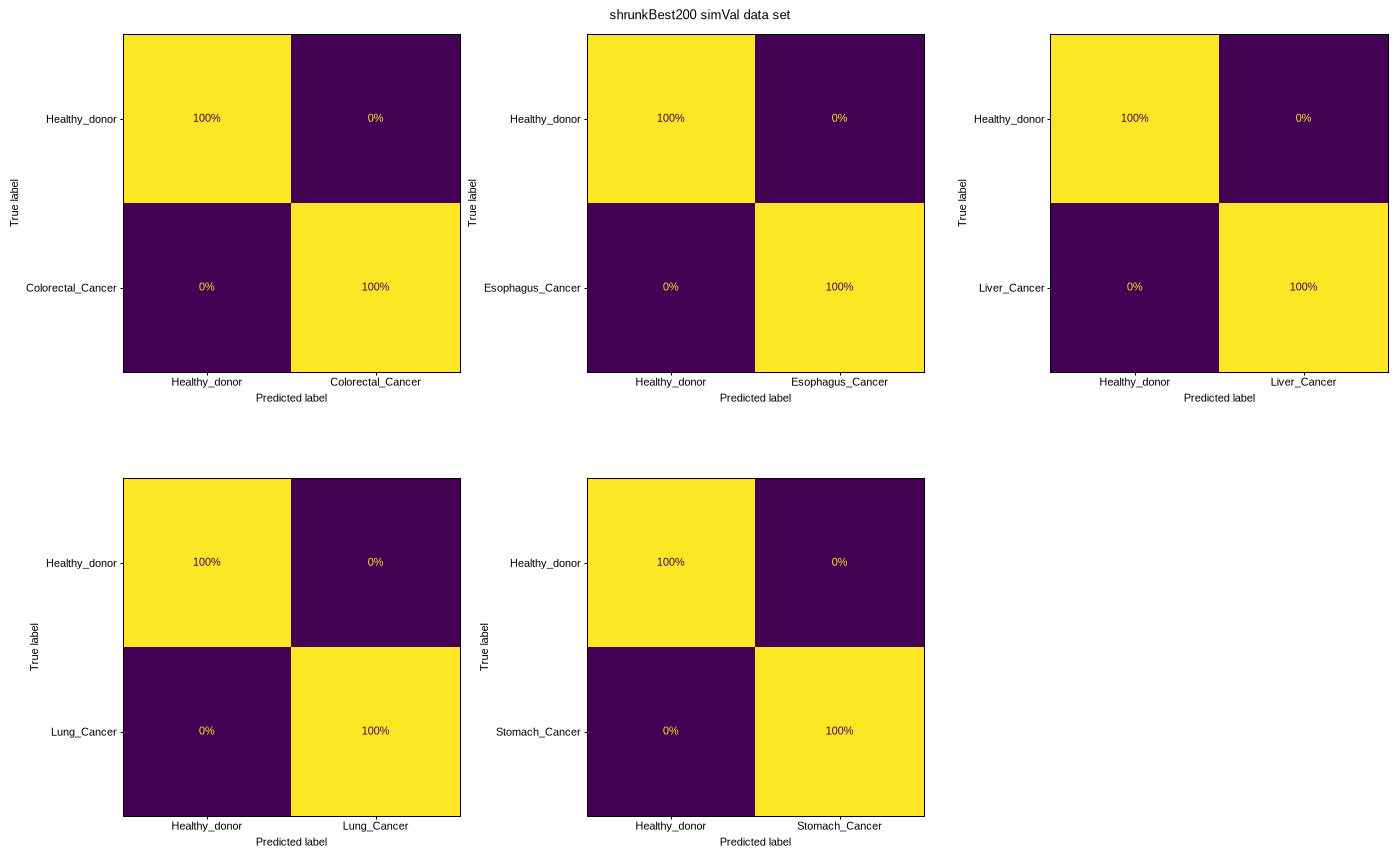

2026-10-20 13:19:29,176 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/confusionMatrix_shrunkBest200-simVal-data-set.png]
2026-10-20 13:19:31,805 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/confusionMatrix_shrunkBest200-simVal-data-set.pdf]


In [11]:
configConfusionPanel( runConfig, "simVal" )

# Evaluate Models train on simulated data using Real hold out examples

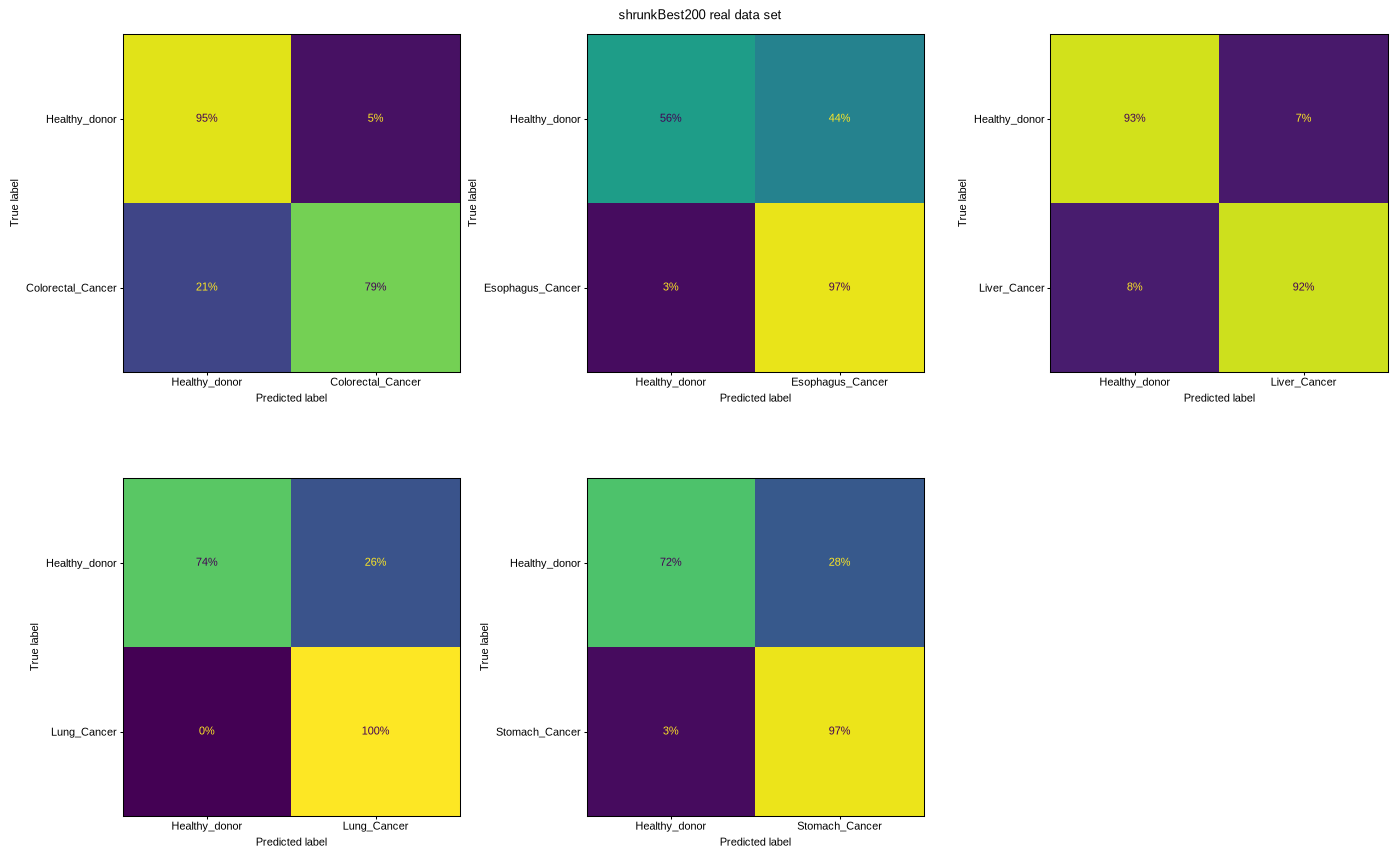

2026-10-20 13:19:35,491 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/confusionMatrix_shrunkBest200-real-data-set.png]
2026-10-20 13:19:37,976 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/confusionMatrix_shrunkBest200-real-data-set.pdf]


In [12]:
configConfusionPanel( runConfig, "real" )

2026-10-20 13:19:37,988 WARNING 1355162540.py <module>() line:1] [AEDWIP TODO REFACTOR]


shrunkBest200 real Data Set Sensitivity (True Positive Rate) and Specificity (True Negative Rate)


,sensitivity,specificity
Colorectal_Cancer,0.79,0.95
Esophagus_Cancer,0.97,0.56
Liver_Cancer,0.92,0.93
Lung_Cancer,1.00,0.74
Stomach_Cancer,0.97,0.72


2026-10-20 13:19:38,163 WARNING plotUtilities.py saveDataFrameImage() line:204] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/realSensAndSpecDF.png]
2026-10-20 13:19:38,240 WARNING plotUtilities.py saveDataFrameImage() line:207] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/realSensAndSpecDF.pdf]


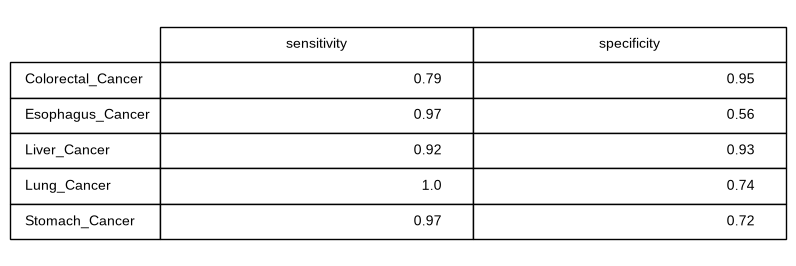

In [13]:
logger.warning("AEDWIP TODO REFACTOR")

def displaySensitivityAndSpecificity() -> pd.DataFrame:
    sensitivities = []
    specificities = [] 
    indicies = []
    controlClass = "Healthy_donor"
    for key, db in runConfig.dataDict.items():
        realModel = db.real 
        sDict = realModel.statsDict
        for kclass, statsDict in sDict.items():
            if kclass == controlClass:
                continue
            indicies.append(kclass)
            sensitivities.append(statsDict['sensitivity'] )
            specificities.append(statsDict['specificity'])

    retDF =  pd.DataFrame( data={
                                "sensitivity" : sensitivities,
                                "specificity" : specificities
                                },
                            index=indicies ).round(2)
    
    return retDF


sensAndSpecDF = displaySensitivityAndSpecificity()
print(f'{runConfig.dataSetName} real Data Set Sensitivity (True Positive Rate) and Specificity (True Negative Rate)')
display( sensAndSpecDF )

sensAndSpecDFImgPath = f'{runConfig.imgOutDir}/realSensAndSpecDF.png'
saveDataFrameImage(sensAndSpecDF, sensAndSpecDFImgPath)

2026-10-20 13:19:38,388 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]
2026-10-20 13:19:38,705 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]
2026-10-20 13:19:39,032 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]
2026-10-20 13:19:39,343 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]
2026-10-20 13:19:39,659 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]


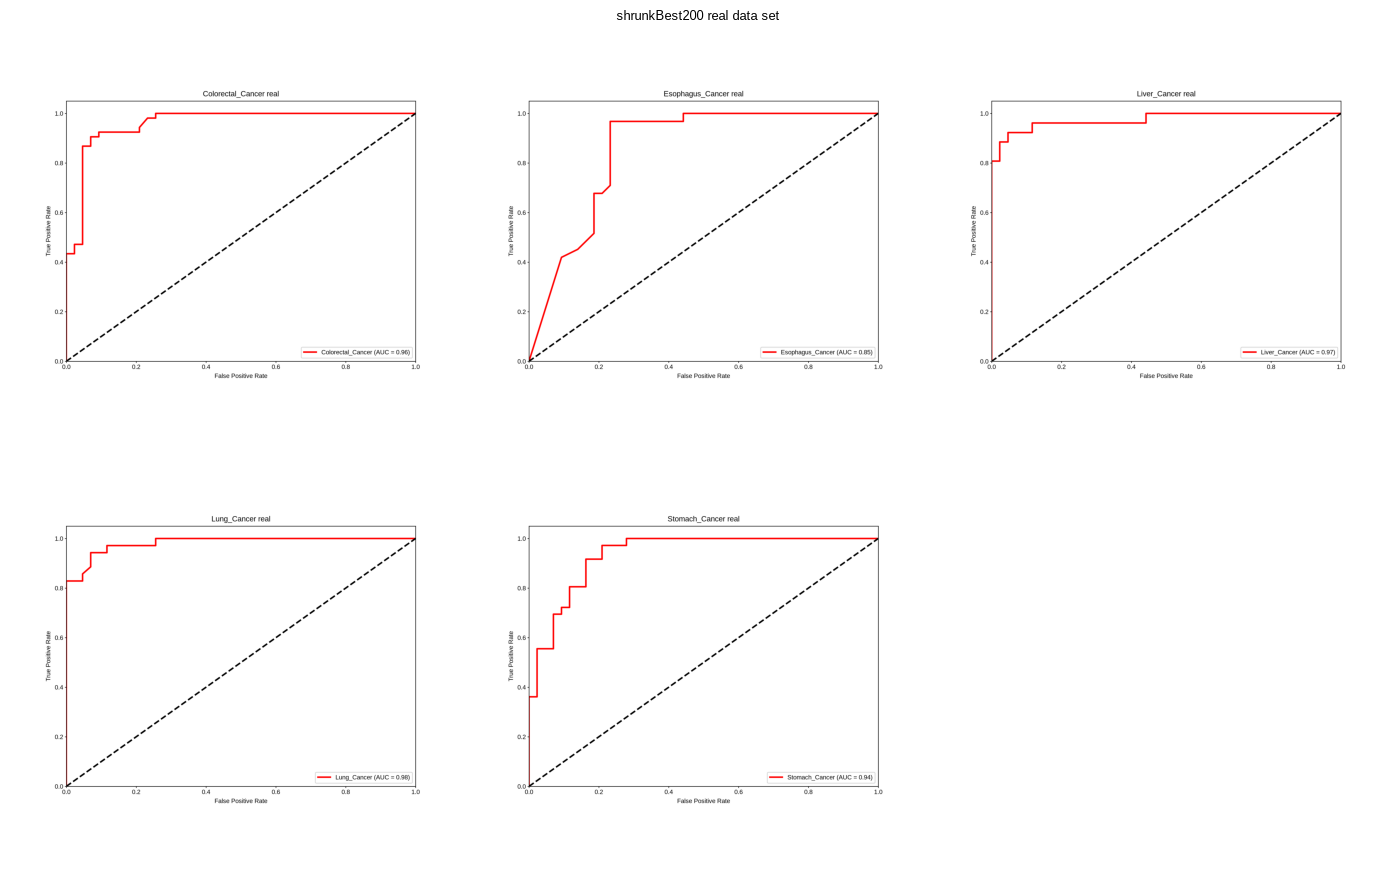

2026-10-20 13:19:52,675 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/ROC_shrunkBest200-real-data-set.png]
2026-10-20 13:20:02,043 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/ROC_shrunkBest200-real-data-set.pdf]


In [14]:
configROCPanel( runConfig, "real" )

2026-10-20 13:20:02,128 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]
2026-10-20 13:20:02,499 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]
2026-10-20 13:20:02,743 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]
2026-10-20 13:20:02,997 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]
2026-10-20 13:20:03,246 WARNING plotPanel.py _fig_to_rgb_array_nondestructive() line:635] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]


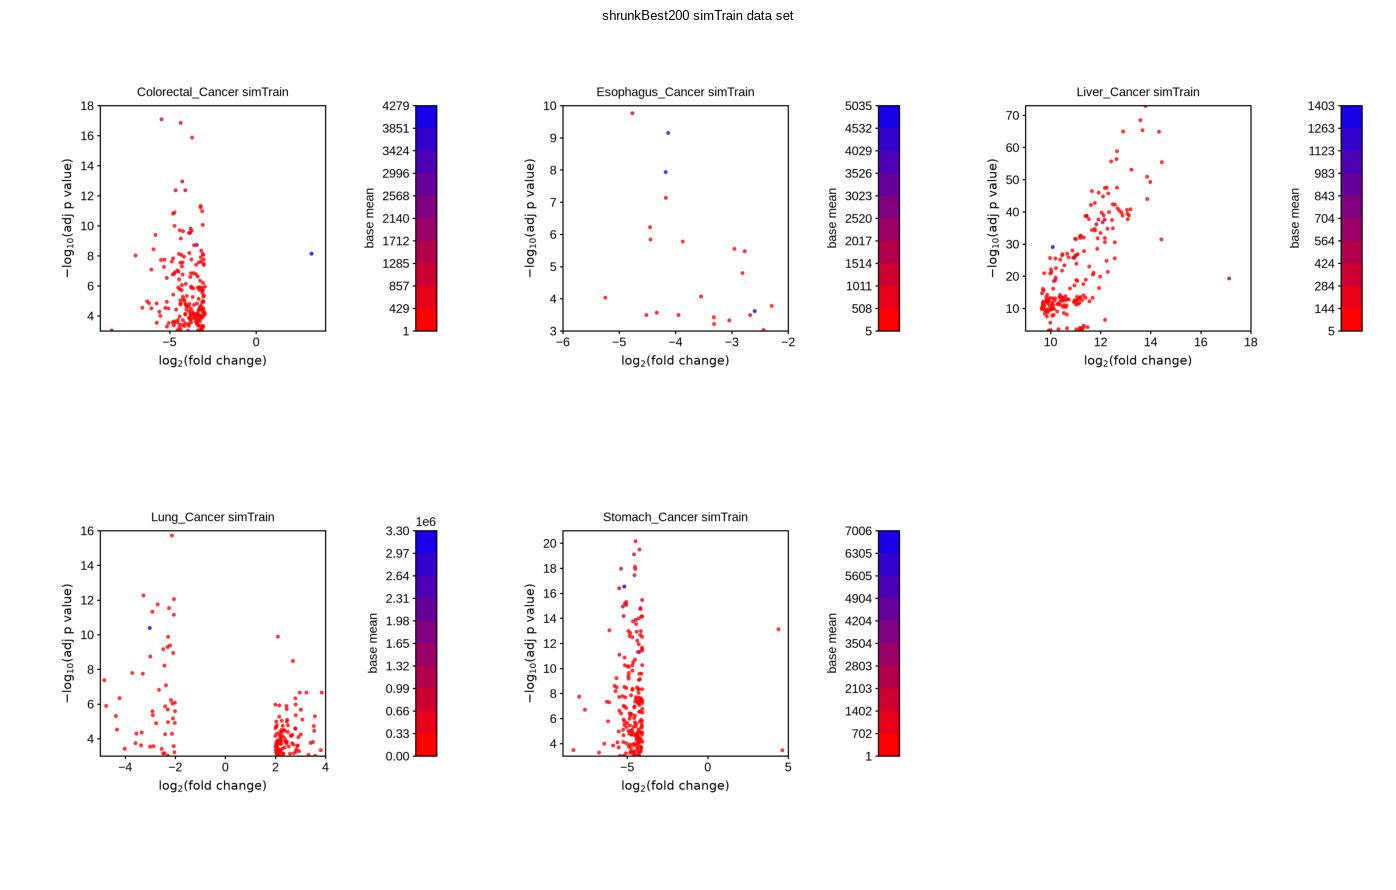

2026-10-20 13:20:12,089 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/volcano_shrunkBest200-simTrain-data-set.png]
2026-10-20 13:20:19,481 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/volcano_shrunkBest200-simTrain-data-set.pdf]


In [15]:
configVolcanoPanel( runConfig )

In [16]:
def aedwipUpsetPlot(config : ModelConfig):
    ''' 
    TODO
    '''
    searchPath = f'{config.simulatedDataPath}/*/*/*.{config.deseqResultsType}' 
    print(searchPath)
    resultsFiles = glob.glob(searchPath)
    # for i in range(len(resultsFiles)):
    #     print(resultsFiles[i])
    
    resultsDict = dict()
    
    for rPath in resultsFiles:
        # fileName = Lung_vs_Healthy_donor.results.lfcShrink
        fileName = rPath.split("/")[-1]
        
        # key = Lung_vs_Healthy_donor
        key = fileName.split(".")[0]
        #print(f'{fileName} {key}')
        # df = pd.read_csv(rPath)
        # print(df.head())
        
        from selectFeatures.driver import _countExtraHeaderLines
        numRowsToSkip = _countExtraHeaderLines(rPath)
        #print(f'\n{key} {numRowsToSkip}')
        deseqDF = pd.read_csv(rPath, skiprows=numRowsToSkip)
        #print(f'{deseqDF.shape}')
        
        resultsDict[key] = deseqDF


    from plots.upsetPlotDataFactory import UpsetPlotDataFactory
    upsetFactory = UpsetPlotDataFactory()
    
    t = upsetFactory.createUpsetPlotDataFromSetDict(resultsDict)
    upsetPlotDataDF, geneSetsDict = t
    
    from selectFeatures.signatureGeneConfig import SignatureGeneConfiguration
    title = f"{config.dataSetName} {config.deseqResultsType}"
    sgc = SignatureGeneConfiguration(
                 dataSetName=config.dataSetName, 
                 design=None, 
                 padjThreshold=None, 
                 lfcThreshold=None, 
                 n=None, 
                 localCacheRootPath=None, 
                 title=title
    )
    
    from plots.upsetPlots import UpsetPlot
    upsetPlot = UpsetPlot(signatureGeneConfig=sgc, 
                          geneSetsDict=geneSetsDict, 
                          geneSetsUpsetPlotData=upsetPlotDataDF
                          )
    
    # full plot, all sets and intersections
    fig, pltDict = upsetPlot.configurablePlot(show_counts=True)
    # plt.suptitle("aEDWIP suptitle")
    
    #
    # find all the intersections
    #
    intersectionDict = upsetPlot.findIntersectionElements()  
    
    return(fig, pltDict, intersectionDict)


fig, pltDict, intersectionDict = aedwipUpsetPlot(runConfig)


/private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/*/*/*.results.lfcShrink
Error in callback <function _draw_all_if_interactive at 0x7fa8391ffe20> (for post_execute), with arguments args (),kwargs {}:


TypeError: only 0-dimensional arrays can be converted to Python scalars

TypeError: only 0-dimensional arrays can be converted to Python scalars

<Figure size 888.889x488.889 with 4 Axes>

In [17]:
logger.error(f'AEDWIP save upset plot')
logger.error(f'AEDWIP save interesection dict')
logger.error(pp.pformat(intersectionDict))

2026-10-20 13:20:27,924 ERROR 886039745.py <module>() line:1] [AEDWIP save upset plot]
2026-10-20 13:20:27,925 ERROR 886039745.py <module>() line:2] [AEDWIP save interesection dict]
2026-10-20 13:20:27,928 ERROR 886039745.py <module>() line:3] [{(np.str_('Colorectal_vs_Healthy_donor'),): ['ENSG00000178394.5',
                                             'ENSG00000009765.15',
                                             'ENSG00000151079.7',
                                             '(GGAG)n',
                                             '(GAGGAG)n',
                                             'ENSG00000237770.2',
                                             'ENSG00000164093.18',
                                             '(CCCCG)n',
                                             '(GGATGG)n',
                                             'ENSG00000118137.10',
                                             'ENSG00000279712.1',
                                             'ENSG00000070193

# Calculate Sensitivity @ Specificity


dataSet shrunkBest200


2026-10-20 13:20:28,474 WARNING 4009396146.py calculateSensitivityAtSpecificty() line:18] [saving : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/shrunkBest200_SensAtSpec.csv]


,diagnosis,Target Specificity,Sensitivity (TPR),Achieved Specificity (TNR),Approx. Threshold,auc,nSimTrainSamples,nSimTrainFeatures,nRealTestSamples,nRealTestFeatures
0,Colorectal,0.9,0.924528,0.9,0.357,0.959193,7999,200,96,200
1,Esophagus,0.9,0.424194,0.9,1.000,0.854839,879,22,74,22
2,Liver,0.9,0.923077,0.9,0.210,0.974955,7999,200,69,200
3,Lung,0.9,0.942857,0.9,0.792,0.982392,6000,150,78,150
4,Stomach,0.9,0.722222,0.9,0.827,0.936047,7999,200,79,200


2026-10-20 13:20:28,952 WARNING plotUtilities.py saveDataFrameImage() line:204] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/realSens@0.png]
2026-10-20 13:20:29,244 WARNING plotUtilities.py saveDataFrameImage() line:207] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/realSens@0.pdf]


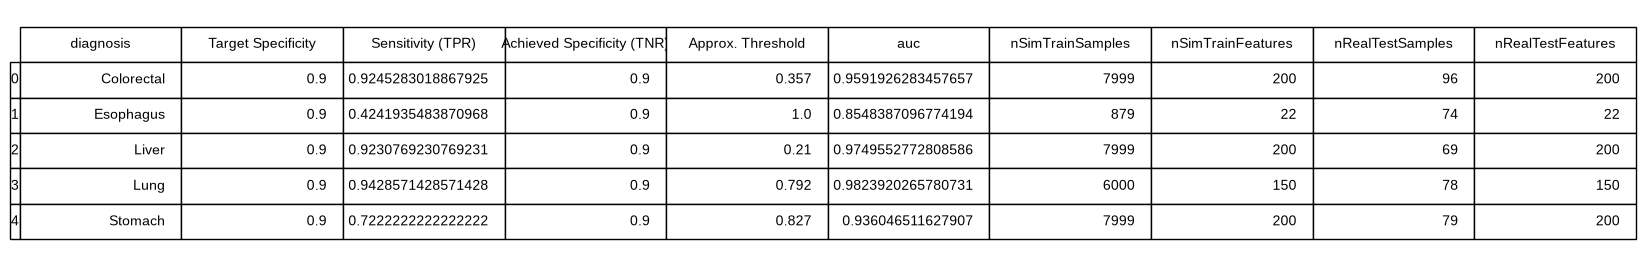

In [18]:
def calculateSensitivityAtSpecificty(
        config : ModelConfig
    ) -> pd.DataFrame:
    """ 
    TODO
    
    similar to multiclass version
    
    returns senitivityAtSpecificityDF
    """ 
    specificityTarget=0.9
    senitivityAtSpecificityDF = configBinaryCalculateSensitivityAtSpecificity(config,
                                                        specifityTargets = [specificityTarget]
                                                        )
    savePath = f'{config.outDirPath}/{config.dataSetName}_SensAtSpec.csv'
    senitivityAtSpecificityDF.to_csv(savePath, index=False)
    config.resultsDict['senitivityAtSpecificity'] = savePath
    logger.warning(f'saving : {savePath}')
    
    return senitivityAtSpecificityDF
    
print(f'\ndataSet {runConfig.dataSetName}')
ssDF = calculateSensitivityAtSpecificty(runConfig)
display( ssDF )

sensAndSpecDFImgPath = f'{runConfig.imgOutDir}/realSens@0.9SpecDF.png'
saveDataFrameImage(ssDF, sensAndSpecDFImgPath)

In [19]:
print(ssDF.to_markdown(index=True))


|    | diagnosis   |   Target Specificity |   Sensitivity (TPR) |   Achieved Specificity (TNR) |   Approx. Threshold |      auc |   nSimTrainSamples |   nSimTrainFeatures |   nRealTestSamples |   nRealTestFeatures |
|---:|:------------|---------------------:|--------------------:|-----------------------------:|--------------------:|---------:|-------------------:|--------------------:|-------------------:|--------------------:|
|  0 | Colorectal  |                  0.9 |            0.924528 |                          0.9 |               0.357 | 0.959193 |               7999 |                 200 |                 96 |                 200 |
|  1 | Esophagus   |                  0.9 |            0.424194 |                          0.9 |               1     | 0.854839 |                879 |                  22 |                 74 |                  22 |
|  2 | Liver       |                  0.9 |            0.923077 |                          0.9 |               0.21  | 0.974955 |       

In [20]:
archive(runConfig)

2026-10-20 13:20:30,042 WARNING saveDataTypes.py saveTrainedModel() line:112] [saved /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/Colorectal_Cancer/trainedModel/model.joblib]
2026-10-20 13:20:30,049 WARNING saveDataTypes.py saveDiagnosticBundle() line:176] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/Colorectal_Cancer/archive_Colorectal_Cancer.json]
2026-10-20 13:20:30,908 WARNING saveDataTypes.py saveTrainedModel() line:112] [saved /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/Esophagus_Cancer/trainedModel/model.joblib]
2026-10-20 13:20:30,911 WARNING saveDataTypes.py saveDiagnosticBundle() line:176] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/Esophagus_Cancer/archive_Esophagus_Cancer.json]
2026-10-20 13:20:31,464 WARNING s

### <span style="color:red;background-color:yellow;">9/8/26 modified ROC AUC plots to show sensitivity as specificity for manuscript</span>

diganosis : Colorectal dataSet : real


2026-10-20 13:20:32,629 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Colorectal-cancer-real.png]
2026-10-20 13:20:32,726 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Colorectal-cancer-real.pdf]


diganosis : Esophagus dataSet : real


2026-10-20 13:20:33,111 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Esophagus-cancer-real.png]
2026-10-20 13:20:33,215 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Esophagus-cancer-real.pdf]


diganosis : Liver dataSet : real


2026-10-20 13:20:33,566 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Liver-cancer-real.png]
2026-10-20 13:20:33,664 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Liver-cancer-real.pdf]


diganosis : Lung dataSet : real


2026-10-20 13:20:34,013 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Lung-cancer-real.png]
2026-10-20 13:20:34,109 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Lung-cancer-real.pdf]


diganosis : Stomach dataSet : real


2026-10-20 13:20:34,462 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Stomach-cancer-real.png]
2026-10-20 13:20:34,558 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/rocSensitivityAtSpecificity_Stomach-cancer-real.pdf]


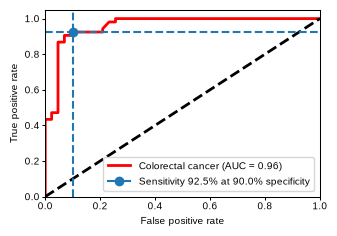

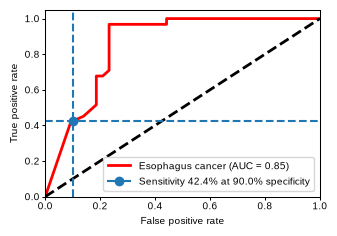

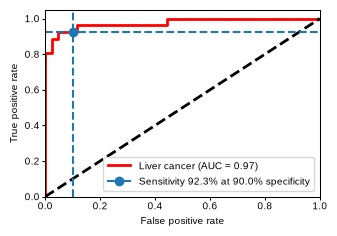

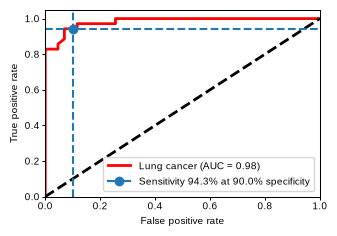

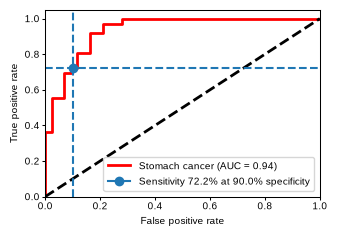

In [21]:
from archive.archiveUtilities import saveFigure
from plots.plotROCCurve import plotROCCurve
from utilities import isOrderedCategoricalSeries

# ref :
# configMLWorkflow configEvaluate()
# mlWorkflow evaluate ()
# debugSensitivity = 0.924528 
# debugSpecificityAt = 0.9


def plotROCManuscript(
        panelWidthInMM : int,
        panelHeightInMM : int,
        fontSize : int = 7, 
    ) -> list[plt.figure]:
    '''
    create an ROC-AUC plot for each diagnosis with a lines showing
    sensitivity @ 90% specificity on the ROC plot
    
    assumes the plots will be assembled into a 2 x 3 panel
    
    fontSize default 7pt is nature bio medical engineerings max size. min is 5pt
   
        
    '''
    plotSSDF = ssDF.set_index("diagnosis")

    # assume 2 columns.
    widthInInches = (panelWidthInMM / 2) / 25.4
    
    # assume three rows
    heightInInches = (panelHeightInMM / 3) / 25.4
    
    retListofFigs = []
    for  dataSet in [ "real"]:
            for diganosis, diagnosticBundle in runConfig.dataDict.items():
                print(f'diganosis : {diganosis} dataSet : {dataSet}')
                #evaluate(diagnosticBundle, dataSet=dataSet, outDirArg=config.imgOutDir)
                
                modelBundle = getattr(diagnosticBundle, dataSet)

                XDF = modelBundle.X
                model = modelBundle.model
                
                # ySeries value type is an ordered pd.Categorical 
                ySeries = modelBundle.y
                if not isOrderedCategoricalSeries(ySeries):
                    errMsg = f'argument ySeries {type(ySeries)} expected pandas series with an ordered categorical dtype'
                    logger.error(errMsg)
                    raise TypeError(errMsg)
                    
                # we need the title to save the file
                # do not pass a title to the plot function.
                # we are going to create a single panel.
                # we want the panel to be as small and tight as possible
                #
                # 'Stomach_Cancer' ->  'Stomach cancer' text.replace("_C", " c")
                diagnosis = diagnosticBundle.diagnosis.replace("_C", " c")
                title = f'{diagnosis} {dataSet}'
                fig, ax, aucDict = plotROCCurve(
                    model=model,
                    XDF=XDF ,
                    ySeries=ySeries,
                    figsize=(widthInInches, heightInInches),
                    title=None, # title,
                    )
                
                retListofFigs.append(fig)
                
                sensitivity, specificity = plotSSDF.loc[ diganosis , ['Sensitivity (TPR)', 'Achieved Specificity (TNR)']]
                
                # add sensitivity@specifity
                # fpr = 1.0 - debugSpecificityAt
                fpr = 1.0 - specificity
                
                ax.axvline(
                    x=fpr,
                    linestyle='--',
                )

                ax.axhline(
                    # y=debugSensitivity,
                    y=sensitivity,
                    linestyle='--',
                )
                
                ax.plot(
                    fpr,
                    # debugSensitivity,
                    sensitivity,
                    marker='o',
                    # label=f'Sensitivity {debugSensitivity:.1%} @ {debugSpecificityAt:.1%} Specificity'
                    # label=f'Sensitivity {sensitivity:.1%} @ {specificity:.1%} Specificity'
                    label=f'Sensitivity {sensitivity:.1%} at {specificity:.1%} specificity'
                )
                
                # we need to rebuild the legend before we make changes
                ax.legend()

                # change the font sizes, 
                # when we shrink the plots to create a panel the fonts are to small
                ax.tick_params(axis='both', labelsize=fontSize)
                ax.xaxis.label.set_size(fontSize)
                ax.yaxis.label.set_size(fontSize)
                ax.title.set_fontsize(fontSize)
                
                # fix capitalization
                # False Positive Rate -> False positive rate
                originalXAxisLabel = ax.get_xlabel()
                ax.set_xlabel(originalXAxisLabel.lower().capitalize())
                
                # True Positive Rate -> True positive rate
                originalYAxisLabel = ax.get_ylabel()
                ax.set_ylabel(originalYAxisLabel.lower().capitalize())

                legend = ax.get_legend()
                if legend is not None:
                    for text in legend.get_texts():
                        text.set_fontsize(fontSize) 
                        # fix capitalization
                        originalText = text.get_text()
                        if 'Cancer' in originalText:
                            newText = (
                                originalText
                                .replace("_", " ")
                                .replace("Cancer", "cancer")
                            )
                            text.set_text(newText)

                    legend.get_title().set_fontsize(fontSize)                       
                
                prefix = "rocSensitivityAtSpecificity"
                outDirArg=runConfig.imgOutDir
                rocPlotPath = saveFigure(fig,  title, outDirArg, prefix)
                # resultsDict['rocFig'] = rocPlotPath
    
    return retListofFigs

rocManuscriptFigs : list[plt.figure] = plotROCManuscript(
    panelWidthInMM=180,
    panelHeightInMM=185,
)

# <span style="color:red;background-color:yellow;">10/2/26 create final artwork</span>
panel width = 180 mm == 7.09 inches
panel height = 185 mm == 7.28 inches

figsize = (180/25.4, 185/25.4)

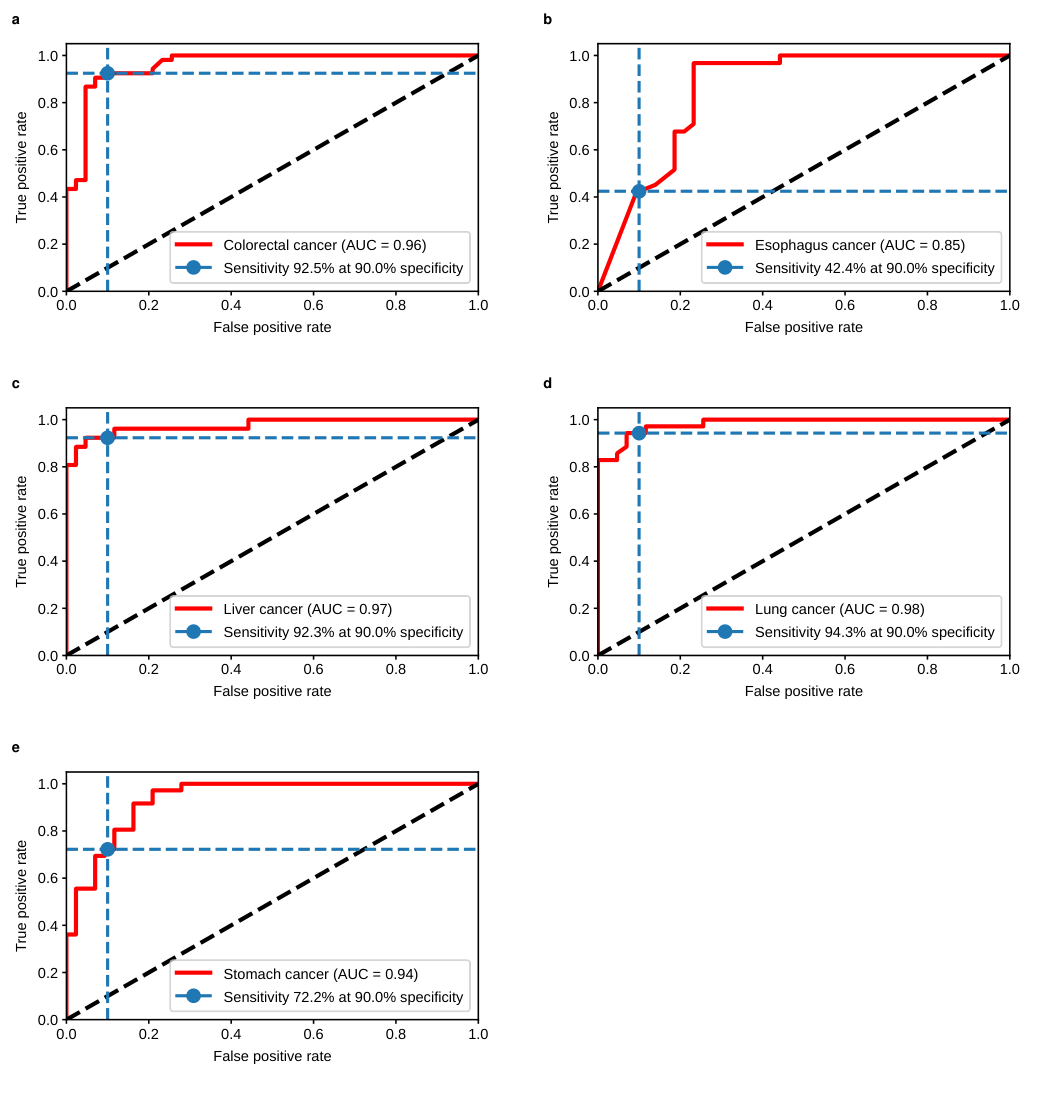

PosixPath('/private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/manuscript/rocSensitivityAt90Specificity.pdf')

In [22]:

rocManuscriptOutputStem = f'{runConfig.imgPanelOutDir}/manuscript/rocSensitivityAt90Specificity'
rocManuscriptPdfPath, rocManuscriptPngPath = combineFigures(
                rocManuscriptFigs,
                rocManuscriptOutputStem,
                bottomMargin=0.20
                )

displayPDFInNotebook(rocManuscriptPdfPath)
rocManuscriptPdfPath

In [23]:
fooDF = ssDF.set_index("diagnosis")
print(fooDF.columns)
fooDF

Index(['Target Specificity', 'Sensitivity (TPR)', 'Achieved Specificity (TNR)',
       'Approx. Threshold', 'auc', 'nSimTrainSamples', 'nSimTrainFeatures',
       'nRealTestSamples', 'nRealTestFeatures'],
      dtype='str')


,Target Specificity,Sensitivity (TPR),Achieved Specificity (TNR),Approx. Threshold,auc,nSimTrainSamples,nSimTrainFeatures,nRealTestSamples,nRealTestFeatures
diagnosis,,,,,,,,,
Colorectal,0.9,0.924528,0.9,0.357,0.959193,7999,200,96,200
Esophagus,0.9,0.424194,0.9,1.000,0.854839,879,22,74,22
Liver,0.9,0.923077,0.9,0.210,0.974955,7999,200,69,200
Lung,0.9,0.942857,0.9,0.792,0.982392,6000,150,78,150
Stomach,0.9,0.722222,0.9,0.827,0.936047,7999,200,79,200


## <span style="color:red;background-color:yellow;">10/20/22 create Extended Data Figure F_R3_1 Binary classifier performance on independent real samples: simulated training vs. Reggiardo et al. final artwork</span>

values copied from 
1. Reggiardo, R. E. et al. Profiling of repetitive RNA sequences in the blood plasma of patients with cancer. Nat. Biomed. Eng 1–9 (2023) doi:10.1038/s41551-023-01081-7.


In [24]:
comparisonDF = pd.DataFrame(
    [
        # Diagnosis    Source                 AUC   Sensitivity  Training  Test  Features
        ("Colorectal", "Simulated training",   0.96, 0.92,        7999,     97,   200),
        ("Colorectal", "Reggiardo et al.",     0.95, 0.70,          79,     18,   109),

        ("Esophagus", "Simulated training",    0.85, 0.42,         879,     74,    22),
        ("Esophagus", "Reggiardo et al.",      0.87, 0.83,          61,     14,    19),

        ("Liver", "Simulated training",        0.97, 0.92,        7999,     70,   200),
        ("Liver", "Reggiardo et al.",          0.94, 0.80,          57,     13,   201),

        ("Lung", "Simulated training",         0.98, 0.94,        6000,     79,   150),
        ("Lung", "Reggiardo et al.",           0.94, 0.71,          64,     15,  2118),

        ("Stomach", "Simulated training",      0.93, 0.72,        7999,     79,   200),
        ("Stomach", "Reggiardo et al.",        0.96, 1.00,          64,     15,   118),
    ],
    columns=[
        "diagnosis",
        "source",
        "auc",
        "sensitivity",
        "trainingSamples",
        "testSamples",
        "features",
    ],
)

In [25]:
def plotBinaryComparisonFinalArtwork(
    df: pd.DataFrame,
    column: str,
    fontSize: float = 7,
    *, # * means all arguments after it must be passed by name.
    widthInMM: float = 85,
    heightInMM: float = 65,
    showLegend: bool = False,
    tickFontSize: float = 6,
    barLabelFontSize: float = 6,
    ) -> tuple[Figure, Axes]:
    """
    Create one grouped bar-chart panel comparing the two sources.
    """

    # ylabel, logarithmic scale, limits
    settings = {
        "auc": (
            # "AUC", False, (0, 1.10)
            "AUC", False, (0, 1.15)
        ),
        "sensitivity": (
            "Sensitivity at 90% specificity", False, (0, 1.10)
        ),
        "trainingSamples": (
            "Training samples", True, (10, 100_000)
        ),
        "testSamples": (
            "Test samples", False, (0, 120)
        ),
        "features": (
            "Features", True, (10, 10_000)
        ),
    }

    if column not in settings:
        raise ValueError(f"column must be one of {list(settings)}")

    sources = ["Simulated training", "Reggiardo et al."]
    colors = ["#40358C", "#168580"]

    # Preserve diagnosis order from the input DataFrame.
    diagnoses = df["diagnosis"].drop_duplicates().tolist()
    values = (
        df.pivot(index="diagnosis", columns="source", values=column)
        .reindex(index=diagnoses, columns=sources)
    )

    if values.isna().any().any():
        raise ValueError("Each diagnosis must have a value for both sources.")

    ylabel, logScale, limits = settings[column]
    isScore = column in {"auc", "sensitivity"}

    style = {
        "font.family": "Arial",
        "font.size": fontSize,
        "font.weight": "normal",
        "axes.labelsize": fontSize,
        "axes.labelweight": "normal",
        "axes.titlesize": fontSize,
        # "xtick.labelsize": fontSize,
        # "ytick.labelsize": fontSize,
        "xtick.labelsize": tickFontSize,
        "ytick.labelsize": tickFontSize,
        "legend.fontsize": fontSize,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }

    with mpl.rc_context(style):
        fig, ax = plt.subplots(
            figsize=(widthInMM / 25.4, heightInMM / 25.4),
            layout="constrained",
        )

        x = np.arange(len(diagnoses))
        # barWidth = 0.36
        barWidth = 0.32
        barSeparation = 0.46  # Distance between the two bar centers

        for i, (source, color) in enumerate(zip(sources, colors)):
            y = values[source].to_numpy()

            bars = ax.bar(
                # x + (i - 0.5) * barWidth,
                x + (i - 0.5) * barSeparation,
                y,
                width=barWidth,
                color=color,
                label=source,
                linewidth=0,
                zorder=3,
            )

            labels = [
                f"{value:.2f}" if isScore else f"{value:,.0f}"
                for value in y
            ]
            # ax.bar_label(
            #     bars,
            #     labels=labels,
            #     padding=2,
            #     fontsize=fontSize,
            #     fontweight="normal",
            # )
            
            # Stagger labels in panels where paired values are close together.
            # This separates labels such as 0.96 / 0.95 and 200 / 201 vertically.
            labelPadding = 2
            # if column in {"auc", "features"} and i == 1:
            #     labelPadding += barLabelFontSize + 1

            ax.bar_label(
                bars,
                labels=labels,
                padding=labelPadding,
                fontsize=barLabelFontSize,
                fontweight="normal",
                zorder=10,  # Keep every label above both series of bars
            )

        ax.set_xticks(x)
        ax.set_xticklabels(diagnoses, rotation=35, ha="right")
        ax.set_xlabel('Cancer diagnosis')
        
        if column == "sensitivity":
            ax.set_ylabel("Sensitivity at\n90% specificity")
        else:
            ax.set_ylabel(ylabel)
        # ax.set_ylabel(ylabel)

        if logScale:
            ax.set_yscale("log")
            ax.minorticks_off()
        elif isScore:
            ax.set_yticks(np.arange(0, 1.01, 0.2))

        ax.set_ylim(*limits)
        ax.set_axisbelow(True)
        ax.grid(axis="y", linestyle="--", linewidth=0.4, alpha=0.35)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(axis="x", length=0)

        if showLegend:
            ax.legend(
                loc="upper center",
                bbox_to_anchor=(0.5, -0.32),
                ncol=2,
                frameon=False,
            )

    # fig.tight_layout()
    return fig, ax

In [26]:
figureWidthMM = 180
panelAreaHeightMM = 102
legendHeightMM = 8

panelWidthMM = 58
panelHeightMM = 48

binaryComparisonLayout: dict[str, Panel] = {
    "a": Panel(
        label="a",
        leftMm=1, topMm=2,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
    "b": Panel(
        label="b",
        leftMm=61, topMm=2,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
    "c": Panel(
        label="c",
        leftMm=121, topMm=2,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
    "d": Panel(
        label="d",
        leftMm=31, topMm=52,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
    "e": Panel(
        label="e",
        leftMm=91, topMm=52,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
}

layout[a].widthMm : 58
layout[a].heightMm : 48
layout[b].widthMm : 58
layout[b].heightMm : 48
layout[c].widthMm : 58
layout[c].heightMm : 48
layout[d].widthMm : 58
layout[d].heightMm : 48
layout[e].widthMm : 58
layout[e].heightMm : 48


2026-10-20 13:20:36,862 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:36,868 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:36,873 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:36,874 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:36,875 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:36,876 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:36,877 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:36,878 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


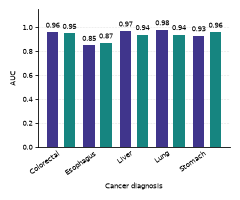

2026-10-20 13:20:38,141 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,142 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,142 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,143 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,144 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,145 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,146 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,147 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


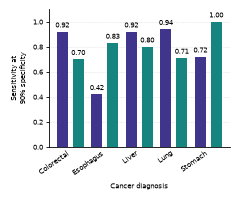

2026-10-20 13:20:38,443 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,444 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,445 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,446 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,447 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,448 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,449 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,450 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


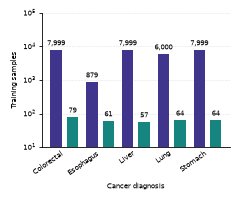

2026-10-20 13:20:38,753 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,754 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,755 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,755 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,756 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,758 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,759 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:38,759 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


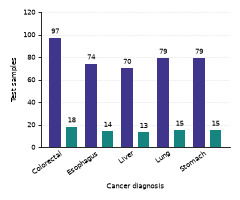

2026-10-20 13:20:39,053 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,054 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,055 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,056 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,057 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,058 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,059 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,060 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


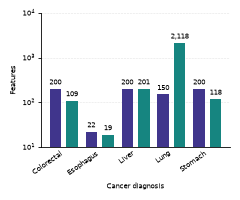

In [27]:
def runFinalArtwork(
                    layout: dict[str, Panel], 
                    fontSize : int = 7
                    ) -> None :
    ''' 
    TODO 
    '''
    panelIdColDict = {
        "a" : "auc", 
        "b" : "sensitivity", 
        "c" : "trainingSamples", 
        "d" : "testSamples", 
        "e" : "features", 
    }
    
    for panelId, col in panelIdColDict.items() : 
        widthMM, heightMm = getSubplotWidthAndHeight(layout, panelId)
        fig, ax = plotBinaryComparisonFinalArtwork(
                                    df=comparisonDF,
                                    column=col,
                                    fontSize=fontSize,
                                    widthInMM=widthMM,
                                    heightInMM=heightMm,
                                    showLegend= False,
                                    tickFontSize=fontSize,
                                    barLabelFontSize=fontSize,
                                    )
        layout[panelId].figure = fig
        
        
runFinalArtwork(binaryComparisonLayout, fontSize=5)


In [28]:
def plotBinaryComparisonLegend(
    widthInMM: float = 180,
    heightInMM: float = 12,
    fontSize: float = 7,
):
    """
    Create a standalone shared legend for the comparison panels.
    """

    fig, ax = plt.subplots(
        figsize=(widthInMM / 25.4, heightInMM / 25.4),
    )
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    ax.set_axis_off()

    handles = [
        Patch(
            facecolor="#40358C",
            edgecolor="none",
            label="Simulated training",
        ),
        Patch(
            facecolor="#168580",
            edgecolor="none",
            label="Reggiardo et al.",
        ),
    ]

    ax.legend(
        handles=handles,
        loc="center",
        ncol=2,
        frameon=False,
        prop={
            "family": "Arial",
            "size": fontSize,
            "weight": "normal",
        },
        handlelength=1.5,
        handletextpad=0.6,
        columnspacing=2,
    )

    return fig, ax

2026-10-20 13:20:39,366 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,367 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,368 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,369 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,370 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,370 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,371 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,372 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


Layout valid: 180 × 118 mm total; panels occupy extents of 179 × 100 mm.


2026-10-20 13:20:39,562 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,563 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,564 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,564 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,565 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,566 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,566 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:39,567 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


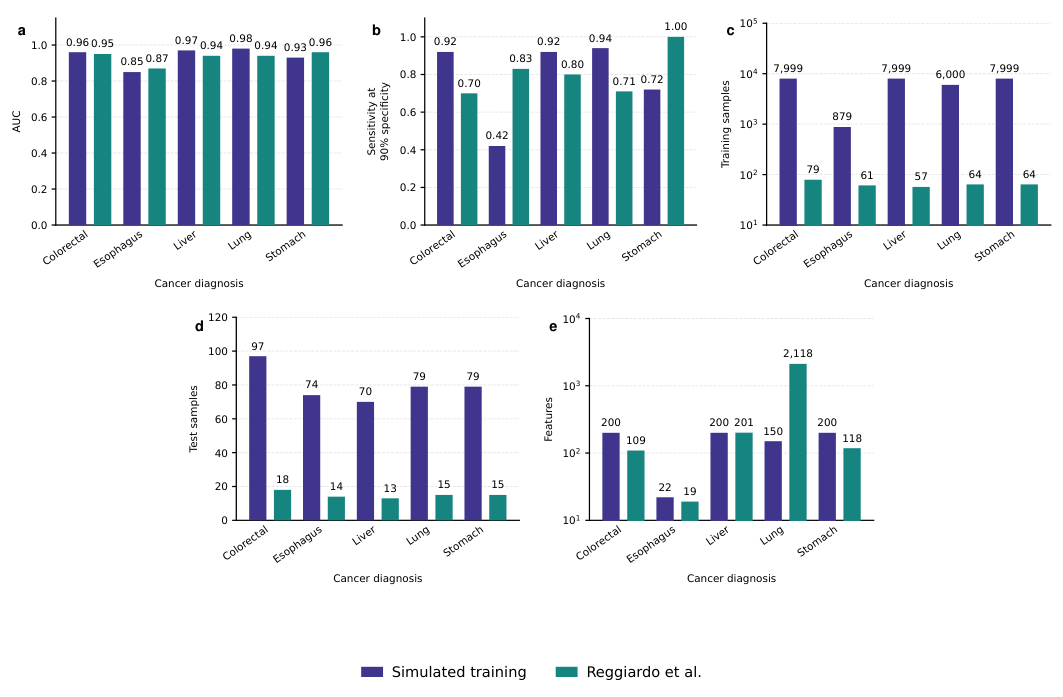

2026-10-20 13:20:42,284 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:42,285 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:42,286 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:42,287 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:42,288 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:42,289 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:42,290 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-20 13:20:42,291 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/binaryClassifierXAI/binaryClassifiers.out/shrunkBest200/img/panel/manuscript/Exd_F_R3_1_binaryComparison.pdf


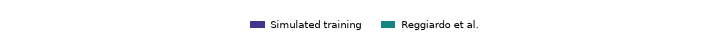

In [29]:
legendFig, legendAx = plotBinaryComparisonLegend(
    widthInMM=figureWidthMM,
    heightInMM=legendHeightMM,
    fontSize=7,
)

outputStem = Path(
    f"{runConfig.imgPanelOutDir}/manuscript/Exd_F_R3_1_binaryComparison"
)
outputStem.parent.mkdir(parents=True, exist_ok=True)

pdfPath, pngPath = combineFiguresLayout(
    panels=binaryComparisonLayout,
    outputStem=outputStem,
    widthMm=figureWidthMM,
    heightMm=panelAreaHeightMM + legendHeightMM,
    legendHeightMm=legendHeightMM,
    legendFigure=legendFig,
)

displayPDFInNotebook(pdfPath)
print(f'saved : {pdfPath}')

In [30]:
logger.warning("END NOTEBOOK")
elapsed = time.time() - notebook_start_time
hours, rem = divmod(elapsed, 3600)
minutes, seconds = divmod(rem, 60)
print(f"✅ Notebook completed in {int(hours)}h {int(minutes)}m {seconds:.1f}s.")

2026-10-20 13:20:42,355 WARNING 2279843384.py <module>() line:1] [END NOTEBOOK]


✅ Notebook completed in 0h 4m 56.4s.
